In [101]:
import pandas as pd

In [102]:
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [103]:
df.columns = df.columns.str.lower()

In [104]:
df.describe().round(2)

,passengerid,survived,pclass,age,sibsp,parch,fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


In [105]:
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare','embarked', 'survived']
df = df[features]
df.isnull().sum()
df.embarked = df.embarked.fillna('Unknown')
df.isnull().sum()

pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      0
survived      0
dtype: int64

In [106]:
df.pclass.value_counts()

pclass
3    491
1    216
2    184
Name: count, dtype: int64

In [107]:
pclass_map = {
    1: 'first',
    2: 'second',
    3: 'third'
}
df.pclass = df.pclass.map(pclass_map)

In [108]:
df.head()

,pclass,sex,age,sibsp,parch,fare,embarked,survived
0,third,male,22.0,1,0,7.2500,S,0
1,first,female,38.0,1,0,71.2833,C,1
2,third,female,26.0,0,0,7.9250,S,1
3,first,female,35.0,1,0,53.1000,S,1
4,third,male,35.0,0,0,8.0500,S,0


In [109]:
df['family_size'] = df.sibsp + df.parch + 1
df = df.drop(columns=['sibsp', 'parch'])
df.head()

,pclass,sex,age,fare,embarked,survived,family_size
0,third,male,22.0,7.2500,S,0,2
1,first,female,38.0,71.2833,C,1,2
2,third,female,26.0,7.9250,S,1,1
3,first,female,35.0,53.1000,S,1,2
4,third,male,35.0,8.0500,S,0,1


In [110]:
from sklearn.model_selection import train_test_split

In [111]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [112]:
mean_age = df_train.age.mean()

In [113]:
df_train['age'] = df_train.age.fillna(mean_age)
df_val['age'] = df_val.age.fillna(mean_age)
df_test['age'] = df_test.age.fillna(mean_age)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [114]:
y_train = df_train.survived.values
y_val = df_val.survived.values
y_test = df_test.survived.values

del df_train['survived']
del df_val['survived']
del df_test['survived']

In [115]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [116]:
dv = DictVectorizer(sparse=False)

dicts_train = df_train.to_dict(orient='records')
dicts_val = df_val.to_dict(orient='records')
X_train = dv.fit_transform(dicts_train)
dt = DecisionTreeClassifier(max_depth=2)
dt.fit(X_train, y_train)
X_val = dv.transform(dicts_val)
y_pred = dt.predict_proba(X_val)[:,1]
auc = roc_auc_score(y_val, y_pred)
print(auc)



0.7940767519466074


In [117]:
depths = [1,2,3,5,10,15,20]
samples_leaf = [1,3,5,10,15,20,50,100, 200, 500]
scores = []
for d in depths:
    for s in samples_leaf:
        dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=s)
        dt.fit(X_train, y_train)
        X_val = dv.transform(dicts_val)
        y_pred = dt.predict_proba(X_val)[:,1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((d,s,auc))
columns = ['max_depth', 'min_samples_leaf', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)
df_scores_pivot = df_scores.pivot(index='min_samples_leaf', columns=['max_depth'], values=['auc'])
df_scores_pivot.round(3)

auc                                          
max_depth            1      2      3      5      10     15     20
min_samples_leaf                                                 
1                 0.724  0.794  0.839  0.842  0.810  0.766  0.768
3                 0.724  0.794  0.839  0.825  0.822  0.824  0.823
5                 0.724  0.794  0.840  0.822  0.824  0.827  0.832
10                0.724  0.794  0.838  0.841  0.841  0.841  0.837
15                0.724  0.794  0.842  0.844  0.853  0.854  0.853
20                0.724  0.794  0.842  0.844  0.847  0.846  0.847
50                0.724  0.820  0.822  0.828  0.828  0.828  0.828
100               0.724  0.779  0.788  0.788  0.788  0.788  0.788
200               0.733  0.733  0.733  0.733  0.733  0.733  0.733
500               0.500  0.500  0.500  0.500  0.500  0.500  0.500

<Axes: xlabel='None-max_depth', ylabel='min_samples_leaf'>

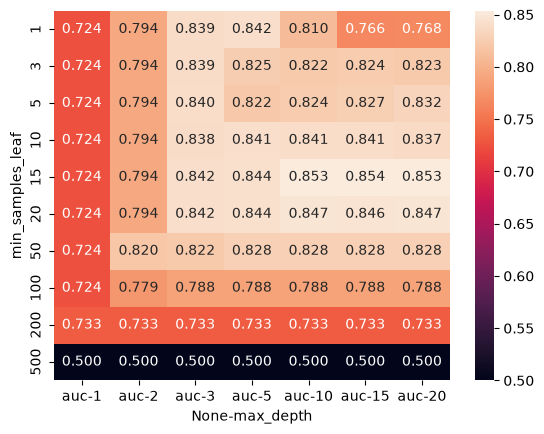

In [118]:
sns.heatmap(df_scores_pivot, annot=True, fmt='.3f')

In [ ]:
max_depth = 15
min_samples_leaf = 15

best_dt = DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=1)

random forest

In [120]:
from sklearn.ensemble import RandomForestClassifier

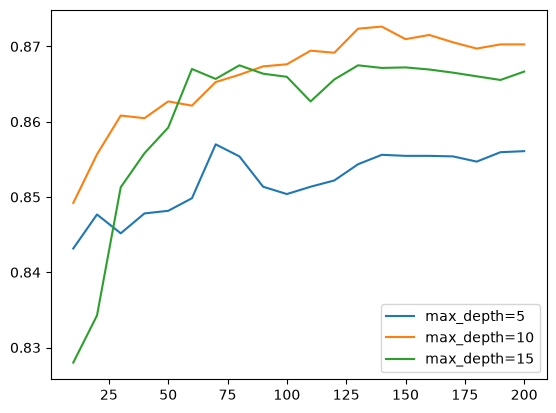

In [121]:
scores = []
tuned_depths = [5,10,15]

for d in tuned_depths:
    for n in range(10, 201, 10):
        rf = RandomForestClassifier(n_estimators=n,
                                max_depth=d,
                                random_state=1)
        rf.fit(X_train, y_train)

        y_pred = rf.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((d, n, auc))
columns = ['max_depth', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)

for d in tuned_depths:
    df_subset = df_scores[df_scores.max_depth == d]

    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='max_depth=%d' % d)

plt.legend()


In [122]:
max_depth = 10

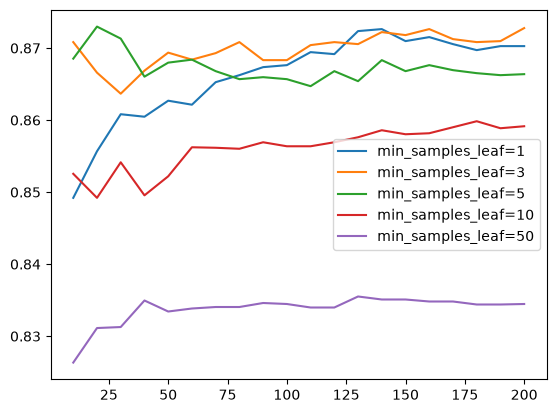

In [123]:
from sklearn.ensemble import RandomForestClassifier

scores = []
samples_leaf = [1,3,5,10,50]

for s in samples_leaf:
    for n in range(10,201,10):
        rf = RandomForestClassifier(n_estimators=n, random_state=1, max_depth=max_depth, min_samples_leaf=s)
        rf.fit(X_train, y_train)
        y_pred = rf.predict_proba(X_val)[:,1]
        auc = roc_auc_score(y_val, y_pred)
        scores.append((s, n, auc))
columns = ['min_samples_leaf', 'n_estimators', 'auc']
df_scores = pd.DataFrame(scores, columns=columns)
for s in samples_leaf:
    df_subset = df_scores[df_scores.min_samples_leaf == s]
    plt.plot(df_subset.n_estimators, df_subset.auc,
             label='min_samples_leaf=%d' % s)
plt.legend()

In [124]:
min_samples_leaf = 3

In [125]:
best_rf = RandomForestClassifier(n_estimators=200, max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=1)


xgboosting

In [126]:
import xgboost as xgb

In [127]:
feature_names = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)


In [128]:
scores = {}

In [134]:
watchlist = [(dtrain, 'train'), (dval, 'val')]

In [ ]:
%%capture output

xgb_params = {
    'eta': 0.3,
    'max_depth': 6,
    'min_child_weight': 1,

    'objective': 'binary:logistic',
    'eval_metric': 'auc',

    'nthread': 8,
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=200,
                  verbose_eval=5,
                  evals=watchlist)

y_pred = model.predict(dval)
roc_auc_score(y_val, y_pred)



In [139]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))
    
    columns = ['num_iter', 'train_auc', 'val_auc']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

In [141]:
df_score = parse_xgb_output(output)

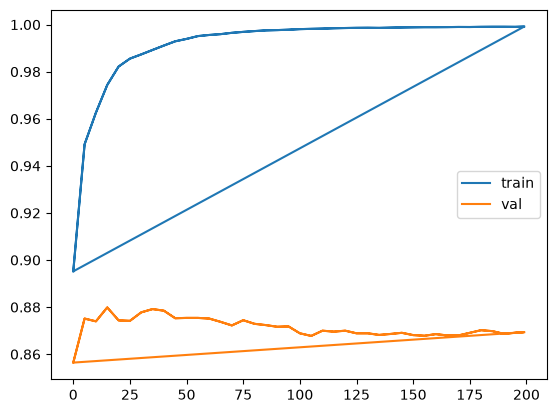

In [ ]:
plt.plot(df_score.num_iter, df_score.train_auc, label='train')
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()

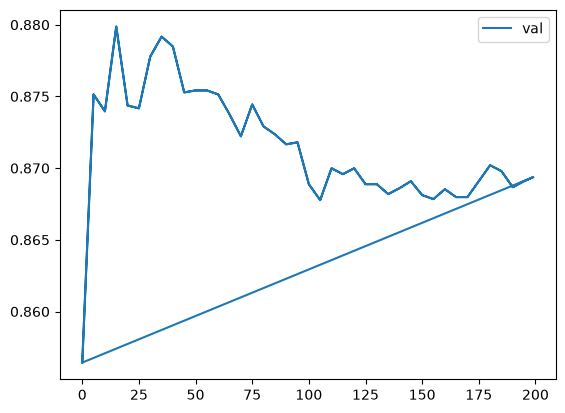

In [144]:
plt.plot(df_score.num_iter, df_score.val_auc, label='val')
plt.legend()